# 07 — Threshold and final evaluation

## Goal of this step

Choose a retention threshold with an explicit cost: missed churner=5, wasted offer=1. Lock that choice using training out-of-fold predictions, then assess the test set once and save the result.

## Why this matters

A probability ranks risk; a threshold decides whom to call. It is like choosing how sensitive a smoke alarm should be: missing a fire is more costly than a false alarm, but too many false alarms also have a cost.

Find the project root and import display tools. Reusable logic lives in src.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np  # noqa: F401
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
assert Path(sys.executable).resolve().is_relative_to(ROOT / ".venv"), "Select the project venv kernel."
%matplotlib inline
plt.rcParams["figure.figsize"] = (8, 4)


The script has already locked a threshold before making its sole held-out prediction. This notebook reads the matching saved report; on a first run, the same function performs that workflow. No fitting ever receives test rows.

In [2]:
from src.evaluate import run_evaluation, plot_threshold, plot_evaluation
from src.config import REPORTS
result = run_evaluation()
display(pd.DataFrame([result['default'], result['cost_selected']], index=['default_0.50', 'training_cost_selected']))

,threshold,roc_auc,pr_auc_ap,precision,recall,f1,brier_score,false_negative,false_positive,cost
default_0.50,0.50,0.844012,0.659178,0.672535,0.513441,0.582317,0.135758,181,93,998
training_cost_selected,0.16,0.844012,0.659178,0.442077,0.892473,0.591273,0.135758,40,419,619


**Interpretation:** ROC-AUC and AP stay the same across thresholds because ranking is unchanged; precision, recall, F1, and business cost depend on the decision rule.

Scan np.linspace(0.05, 0.95, 91) on out-of-fold training predictions. Each customer's score comes from a pipeline that did not fit on that row. Lower thresholds generally catch more churners and send more unnecessary offers.

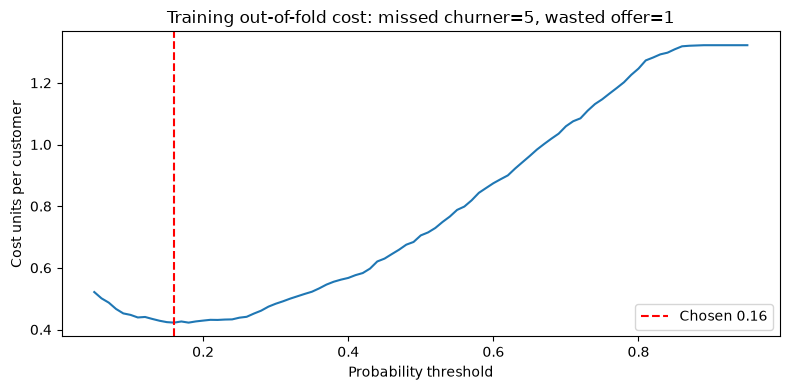

,threshold,false_negative,false_positive,cost,cost_per_customer
11,0.16,150,1622,2372,0.422365
13,0.18,175,1497,2372,0.422365
10,0.15,139,1686,2381,0.423967
12,0.17,166,1563,2393,0.426104
14,0.19,190,1444,2394,0.426282


In [3]:
scan = pd.read_csv(REPORTS / 'threshold_scan.csv')
threshold = result['cost_selected']['threshold']
plot_threshold(scan, threshold, show=True)
display(scan.nsmallest(5, 'cost'))

**Interpretation:** The selected threshold minimizes 5*FN+FP on training OOF predictions; costs assume equal value per customer and do not prove an offer prevents churn. Hyperparameter selection still makes this OOF cost somewhat optimistic.

Read the saved test predictions for confusion, ranking, and calibration plots; this produces no new test inference. Calibration asks whether a predicted 30% risk corresponds to roughly 30% observed churn.

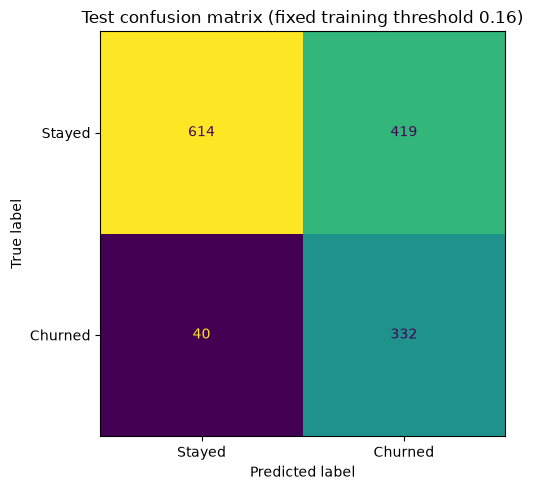

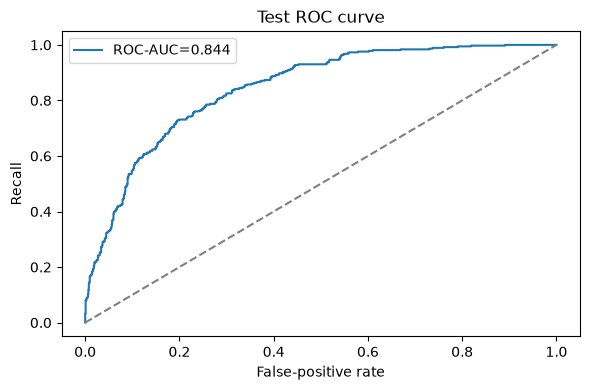

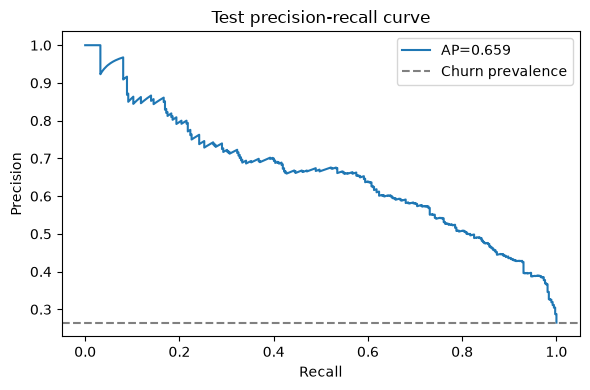

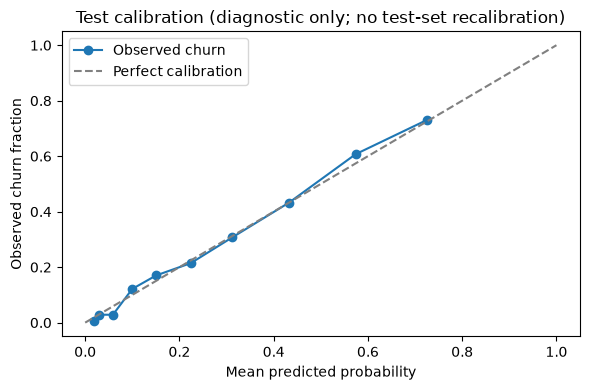

In [4]:
predictions = pd.read_csv(REPORTS / 'test_predictions.csv')
plot_evaluation(predictions, threshold, show=True)

**Interpretation:** The confusion matrix shows the offer tradeoff; ROC and PR summarize ranking; departures from the calibration diagonal suggest probabilities need future validation, not recalibration on this test set.

Compare training CV AP with the single test AP. Fold SD describes variation, not a formal uncertainty interval for this difference.

In [5]:
display(pd.Series({'tuned_CV_AP': result['tuned_cv_ap'], 'CV_fold_SD': result['tuned_cv_ap_std'], 'test_AP': result['cost_selected']['pr_auc_ap'], 'test_minus_CV_AP': result['test_minus_cv_ap']}))

tuned_CV_AP         0.664591
CV_fold_SD          0.042884
test_AP             0.659178
test_minus_CV_AP   -0.005413
dtype: float64

**Interpretation:** A gap can reflect sampling variation and selection optimism; one random split cannot establish stable performance. No model or threshold is changed after seeing this result.

## Common mistakes

- Selecting the cheapest threshold on test labels.
- Confusing average precision with trapezoidal PR-curve area.
- Assuming ranking quality guarantees calibrated probabilities or retention impact.

## Key takeaways

- The offer threshold is selected entirely from training predictions.
- Held-out predictions are made once and persisted for repeatable notebook execution.
- Cost and calibration complement ranking metrics.

## Next step

08_explainability.ipynb: explain the already-frozen model using training customers.